In [1]:
import pandas as pd

ModuleNotFoundError: No module named 'pandas'

In [2]:
%pip install pandas 

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.6 MB 245.8 kB/s eta 0:00:38
   -- ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\mnave\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

In [6]:
df = pd.read_csv("sample_data_cleaning_project.csv")

In [9]:
df.head()

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [10]:
df.shape

(43, 5)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        43 non-null     str    
 1   Age         39 non-null     float64
 2   Salary      36 non-null     float64
 3   Join_Date   43 non-null     str    
 4   Department  43 non-null     str    
dtypes: float64(2), str(3)
memory usage: 1.8 KB


In [12]:
df.isnull().sum()

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

In [13]:
df[df.isnull().any(axis=1)]

,Name,Age,Salary,Join_Date,Department
1,Jane,NaN,65000.0,8/1/2022,Finance
3,Bob,22.0,NaN,1/15/2023,IT
5,Jade,40.0,NaN,1/15/2023,Finance
8,Sam,40.0,NaN,9/5/2022,IT
9,Eli,NaN,80100.0,3/4/2022,HR
12,Dan,43.0,NaN,1/15/2023,HR
14,Pamela,NaN,77421.0,4/2/2023,HR
17,Dan,43.0,NaN,5/3/2022,HR
24,Tony,NaN,66200.0,5/18/2023,Finance
31,Sam,40.0,NaN,9/5/2022,IT


In [14]:
df[['Age', 'Salary']].describe()

,Age,Salary
count,39.000000,36.000000
mean,34.692308,132729.694444
std,9.624951,196694.464572
min,21.000000,61000.000000
25%,25.000000,66175.000000
50%,36.000000,71841.000000
75%,42.000000,77421.000000
max,57.000000,921000.000000


In [15]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [16]:
df["Salary"] = df["Salary"].fillna(df["Salary"].median())

In [17]:
df.isnull().sum()

Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(1)

In [20]:
df[df.duplicated()]

,Name,Age,Salary,Join_Date,Department
31,Sam,40.0,71841.0,9/5/2022,IT


In [21]:
df = df.drop_duplicates()

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df["Join_Date"] = pd.to_datetime(df["Join_Date"])

In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 42 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Name        42 non-null     str           
 1   Age         42 non-null     float64       
 2   Salary      42 non-null     float64       
 3   Join_Date   42 non-null     datetime64[us]
 4   Department  42 non-null     str           
dtypes: datetime64[us](1), float64(2), str(2)
memory usage: 2.0 KB


In [25]:
df.sort_values("Salary", ascending=False).head()

,Name,Age,Salary,Join_Date,Department
21,Norma,51.0,921000.0,2021-02-04,IT
28,Jenny,36.0,801423.0,2021-09-15,IT
42,Kim,33.0,546222.0,2021-08-30,HR
15,Susy,41.0,126001.0,2023-02-02,IT
18,Joanne,25.0,125600.0,2023-01-16,IT


In [26]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 68500.0
Q3 = 77421.0
IQR = 8921.0


In [27]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit =", lower)
print("Upper limit =", upper)

Lower limit = 55118.5
Upper limit = 90802.5


In [28]:
outliers = df[(df["Salary"] < lower) | (df["Salary"] > upper)]
outliers

,Name,Age,Salary,Join_Date,Department
6,Joanne,25.0,120000.0,2023-01-16,IT
15,Susy,41.0,126001.0,2023-02-02,IT
18,Joanne,25.0,125600.0,2023-01-16,IT
21,Norma,51.0,921000.0,2021-02-04,IT
28,Jenny,36.0,801423.0,2021-09-15,IT
42,Kim,33.0,546222.0,2021-08-30,HR


In [29]:
df["Salary_Cleaned"] = df["Salary"].clip(lower, upper)

In [30]:
df[["Name", "Salary", "Salary_Cleaned"]].sort_values("Salary", ascending=False).head(6)

,Name,Salary,Salary_Cleaned
21,Norma,921000.0,90802.5
28,Jenny,801423.0,90802.5
42,Kim,546222.0,90802.5
15,Susy,126001.0,90802.5
18,Joanne,125600.0,90802.5
6,Joanne,120000.0,90802.5


In [31]:
df["Salary_Cleaned"].describe()

count       42.000000
mean     74140.095238
std       8506.656349
min      61000.000000
25%      68500.000000
50%      71841.000000
75%      77421.000000
max      90802.500000
Name: Salary_Cleaned, dtype: float64

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'matplotlib'

In [33]:
%pip install matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 881.2 kB/s eta 0:00:11
   -- ------------------------------------- 0.5/9.3 MB 881.2 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/9.3 MB 1.0 MB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.3 MB 928.9 kB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.3 MB 928.9 kB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.3 MB 874.8 kB/s eta 0:00:10
   ------ --------------------------------- 1.6/9.3 MB 991.4 kB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 994.7 kB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.3 MB 1.0 MB/s eta 0:00:07
   -------- -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\mnave\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

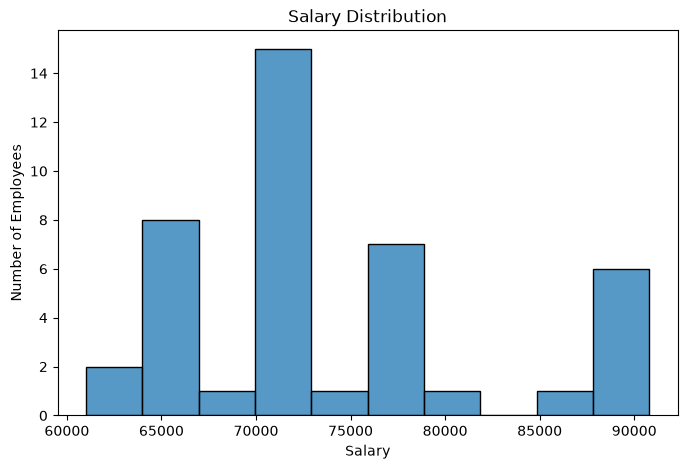

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(df["Salary_Cleaned"], bins=10)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

In [38]:
df["Department"].value_counts()

Department
HR         22
Finance    10
IT         10
Name: count, dtype: int64

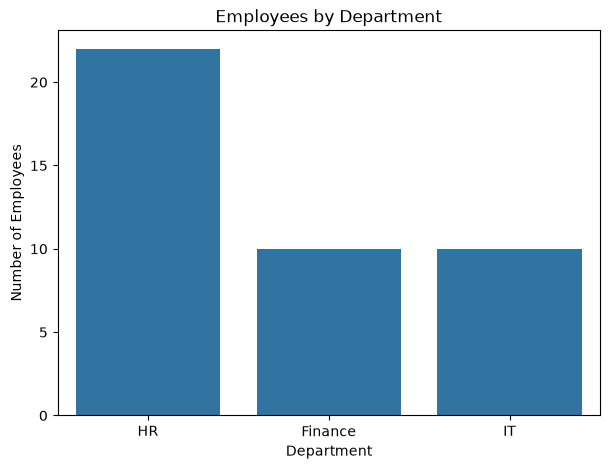

In [39]:
plt.figure(figsize=(7,5))
sns.countplot(x="Department", data=df)
plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.show()

In [40]:
df.groupby("Department")["Salary_Cleaned"].mean()

Department
Finance    65614.100000
HR         74593.113636
IT         81669.450000
Name: Salary_Cleaned, dtype: float64

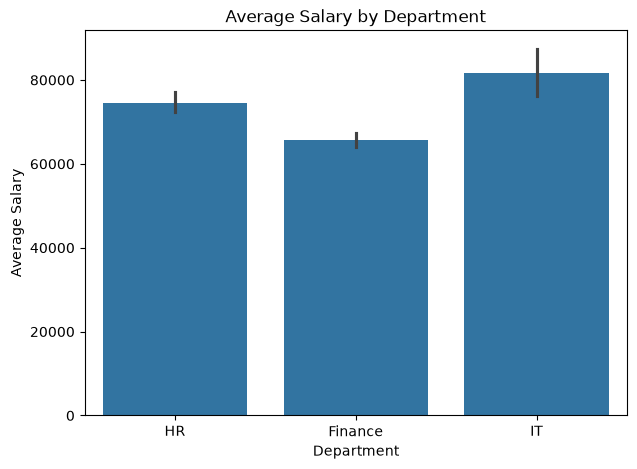

In [41]:
plt.figure(figsize=(7,5))
sns.barplot(x="Department", y="Salary_Cleaned", data=df)
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.show()


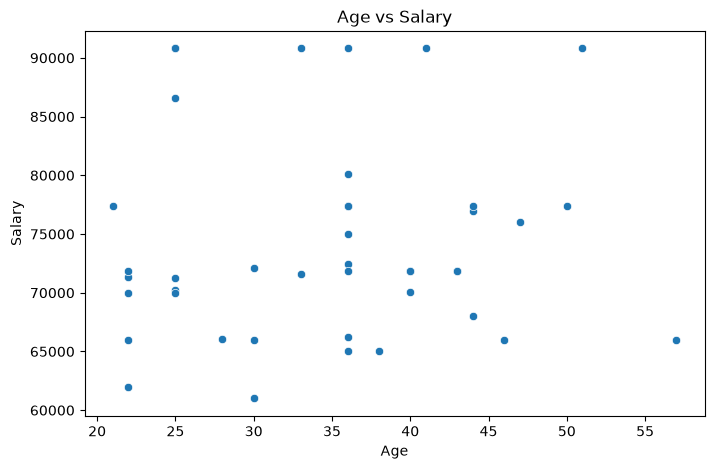

In [42]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="Age", y="Salary_Cleaned", data=df)
plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

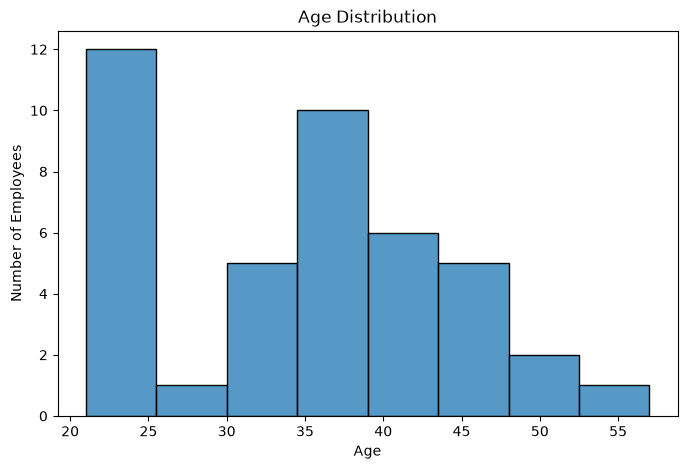

In [43]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=8)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.show()

In [44]:
df["Salary"] = df["Salary_Cleaned"]

In [45]:
df.drop("Salary_Cleaned", axis=1, inplace=True)

In [46]:
df.head()

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,2023-01-15,HR
1,Jane,36.0,65000.0,2022-08-01,Finance
2,Alice,22.0,71350.0,2021-05-20,HR
3,Bob,22.0,71841.0,2023-01-15,IT
4,Pam,25.0,71250.0,2023-01-15,HR


In [47]:
df.isnull().sum()

Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

In [48]:
df.duplicated().sum()

np.int64(1)

In [49]:
df = df.drop_duplicates()

In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df.to_csv("cleaned_sample_data.csv", index=False)

In [52]:
import os
os.path.exists("cleaned_sample_data.csv")

True

In [53]:
df.describe()

,Age,Salary,Join_Date
count,41.000000,41.000000,41
mean,34.926829,73733.695122,2022-08-03 06:26:20.487805
min,21.000000,61000.000000,2021-02-04 00:00:00
25%,25.000000,68000.000000,2022-03-04 00:00:00
50%,36.000000,71841.000000,2022-10-01 00:00:00
75%,41.000000,77421.000000,2023-01-15 00:00:00
max,57.000000,90802.500000,2024-10-03 00:00:00
std,9.223314,8189.145188,NaN


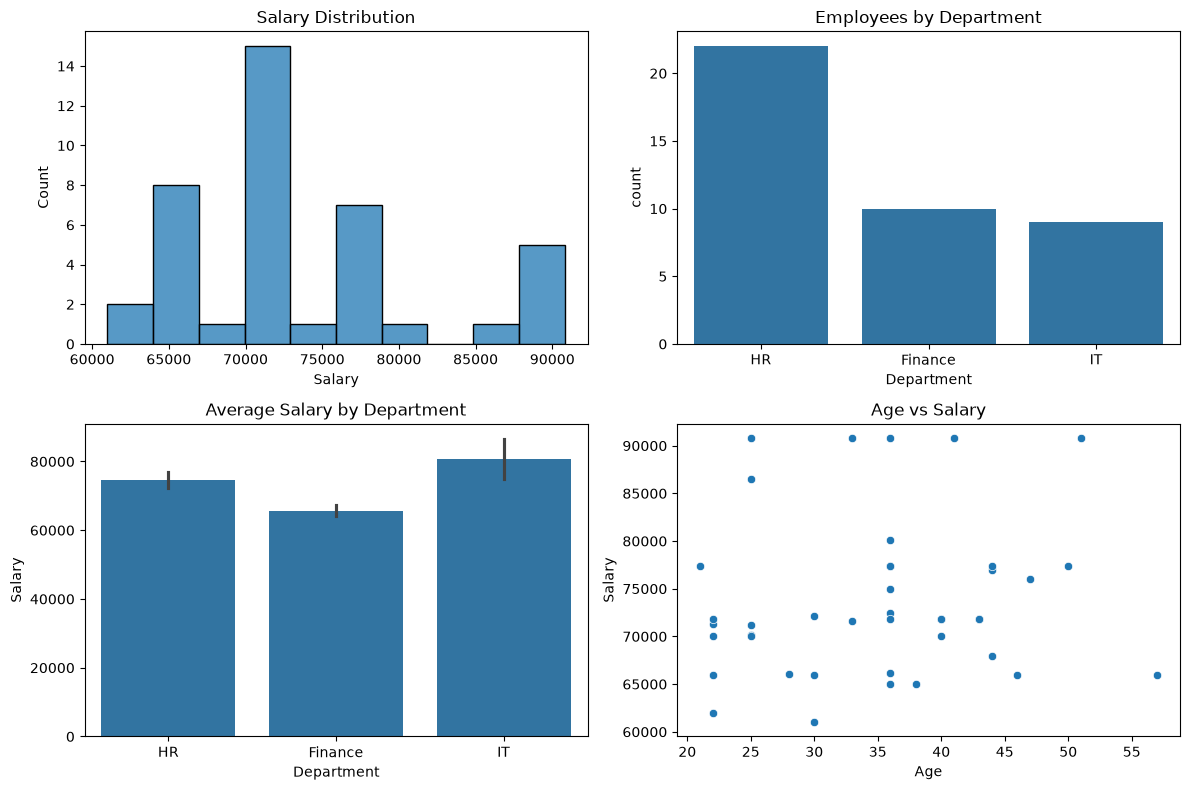

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.histplot(df["Salary"], bins=10)
plt.title("Salary Distribution")

plt.subplot(2, 2, 2)
sns.countplot(x="Department", data=df)
plt.title("Employees by Department")

plt.subplot(2, 2, 3)
sns.barplot(x="Department", y="Salary", data=df)
plt.title("Average Salary by Department")

plt.subplot(2, 2, 4)
sns.scatterplot(x="Age", y="Salary", data=df)
plt.title("Age vs Salary")

plt.tight_layout()
plt.show()